In [1]:
import anndata as ad
import squidpy as sq
import cellcharter as cc
import pandas as pd
import scanpy as sc
import scvi
import numpy as np
import matplotlib.pyplot as plt
from lightning.pytorch import seed_everything

seed_everything(12345)

import os
import bbknn
from scipy import sparse
import matplotlib.pyplot as plt

/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  return module_get_attr_redirect(attr_n

In [2]:
adata = sc.read("/mnt/e/AD .h5ad")

In [14]:
#adata = adata2[adata2.obs['domain'] == 'peri_tumor'].copy()
adata.obsm['spatial'] = adata.obsm['X_spatial']

In [15]:
sc.pp.filter_genes(adata, min_counts=3)
sc.pp.filter_cells(adata, min_counts=50)
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)
adata.obs['batch'] = 1 ###

In [5]:
scvi.model.SCVI.setup_anndata(
    adata, 
    layer="counts", 
    batch_key='batch',
)

model = scvi.model.SCVI(adata)
model.train(early_stopping=True, enable_progress_bar=True)
adata.obsm['X_scVI'] = model.get_latent_representation(adata).astype(np.float32)

/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA RTX 2000 Ada Generation Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/25 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=25` reached.


In [16]:
#
sq.gr.spatial_neighbors(adata, library_key='group', coord_type='generic', delaunay=True,
                        radius=200,
                        spatial_key='spatial', percentile=99)
cc.gr.remove_long_links(adata,distance_percentile = 95.0)



In [7]:
cc.gr.aggregate_neighbors(adata, n_layers=3, use_rep='X_scVI', out_key='X_cellcharter', sample_key='group')
autok = cc.tl.ClusterAutoK(
    n_clusters=(2,10), 
    max_runs=10,
    convergence_tol=0.001
)

#adata.write('/mnt/e/af_region.h5ad')

  0%|          | 0/6 [00:00<?, ?it/s]

In [8]:
autok.fit(adata, use_rep='X_cellcharter')

Iteration 1/10


  0%|          | 0/11 [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVIC

Iteration 2/10


  0%|          | 0/11 [00:00<?, ?it/s]

...

  0%|          | 0/11 [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVIC

Iteration 10/10


  0%|          | 0/11 [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVIC

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


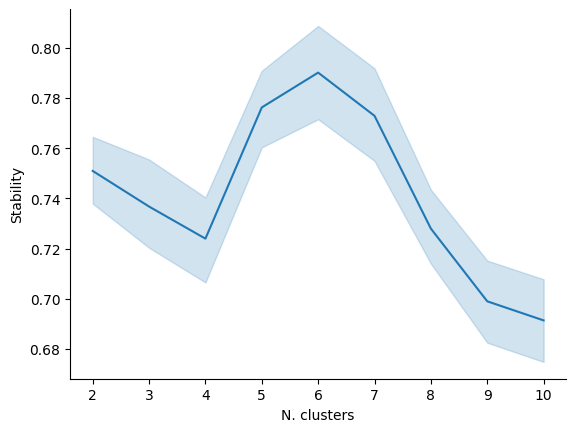

In [9]:
cc.pl.autok_stability(autok)
adata.obs['cluster_cellcharter'] = autok.predict(adata, use_rep='X_cellcharter')


In [10]:
adata.obsm['spatial'] = adata.obsm['spatial'].astype(np.float64)#转换坐标为浮点数
adata.obs['batch'] = adata.obs['batch'].astype('category')
adata

AnnData object with n_obs × n_vars = 434195 × 5006
    obs: 'orig.ident', 'nCount_Xenium', 'nFeature_Xenium', 'Cell_Anno', 'group', 'Type', 'barcode', 'n_counts', 'batch', '_scvi_batch', '_scvi_labels', 'cluster_cellcharter'
    var: 'n_counts'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'spatial_neighbors'
    obsm: 'X_spatial', 'spatial', 'X_scVI', 'X_cellcharter'
    layers: 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [11]:
adata.obs['cluster_cellcharter']

aaaaafno-1_CWD    1
aaaahjae-1_CWD    1
aaaakdoo-1_CWD    1
aaaapapn-1_CWD    1
aaabalnp-1_CWD    1
                 ..
oijgglfa-1_IWD    3
oijgnfga-1_IWD    3
oijhncid-1_IWD    3
oijicmkl-1_IWD    3
oijijfhf-1_IWD    3
Name: cluster_cellcharter, Length: 434195, dtype: category
Categories (6, object): ['0', '1', '2', '3', '4', '5']

/root/miniconda3/envs/cellcharter/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


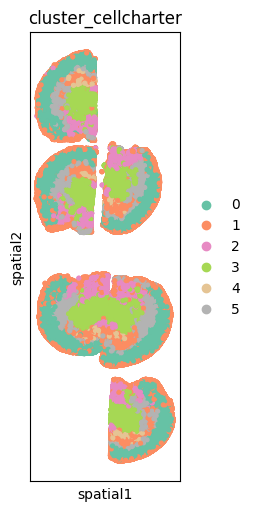

In [12]:
sq.pl.spatial_scatter(
    adata, 
    color=['cluster_cellcharter'], 
    library_key='batch',  
    size=30, 
    img=None, shape=None,
    palette='Set2',
    figsize=(5,5),
    ncols=1
)

In [24]:
print(adata.obs['cluster_cellcharter'].value_counts())

cluster_cellcharter
CN_2    162078
CN_5    151395
CN_3    150900
CN_4     90715
CN_1     61277
Name: count, dtype: int64


In [8]:
##############计算邻域后从下面开始
#adata.write("/mnt/e/Xenium/adata_stroma_CN.h5ad")
adata = sc.read("/mnt/e/AD_analysis/AD_ST hip.h5ad")

In [9]:
celltype_colors = {
    'Neurons_EX': '#D10D0F',
    'Neurons_IN': "#00A6D0",
    'Astro': "#FFB600",
    'Oligo': "#42A24E",
    'OPC': '#0F7240',
    'Micro': '#507BA8',
    'FBs': '#354C85',
    'EC': '#83C5BD',
    'Epen': '#5d2b84',
    'Peri': '#BBB8D7'
}
# 
if not isinstance(adata.obs['Cell_Anno'].dtype, pd.CategoricalDtype):
    adata.obs['Cell_Anno'] = pd.Categorical(adata.obs['Cell_Anno'])

# 
categories = adata.obs['Cell_Anno'].cat.categories
adata.uns['Cell_Anno_colors'] = [celltype_colors[cat] for cat in categories]

adata.obs['Type'].unique()
adata.obs['condition'] = adata.obs['Type'].str.split('-').str[0].astype('category')

In [11]:
adata.obs['Hip']

abaojamg-1_IWD    niche_3
abapbpgb-1_IWD    niche_3
abapdpam-1_IWD    niche_3
abbbdhbo-1_IWD    niche_2
abbbihlg-1_IWD    niche_3
                   ...   
oihfipai-1_CWD    niche_2
oihfmidd-1_CWD    niche_2
oihfnhjp-1_CWD    niche_2
oihfomnh-1_CWD    niche_2
oihiihbn-1_CWD    niche_2
Name: Hip, Length: 41447, dtype: category
Categories (6, object): ['niche_1', 'niche_2', 'niche_3', 'niche_4', 'niche_5', 'niche_6']

In [28]:
#adata_subgroup1 = adata[adata.obs['banksy_niche'] == 'niche_3']
#adata.obs['condition'] = adata.obs['Type'].str.split('-').str[0].astype('category')
#adata_subgroup1 = adata[adata.obs['banksy_niche'].isin(['niche_1', 'niche_4', 'niche_6', 'niche_7'])].copy()
adata_subgroup2 = adata[adata.obs['Hip'] == 'niche_2'].copy()
#adata_subgroup2 = adata_subgroup1[adata_subgroup1.obs['Type'] == 'CWD']

In [25]:
adata_subgroup2

AnnData object with n_obs × n_vars = 8168 × 4014
    obs: 'orig.ident', 'nCount_Xenium', 'nFeature_Xenium', 'group', 'Type', 'nCount_SCT', 'nFeature_SCT', 'Cell_Anno', 'region', 'Hip', 'celltype', 'DG', 'barcode', 'condition', 'n_counts', 'batch'
    var: 'n_counts'
    uns: 'Cell_Anno_colors', 'log1p', 'spatial_neighbors'
    obsm: 'X_pca', 'X_spatial', 'X_umap', 'spatial'
    layers: 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

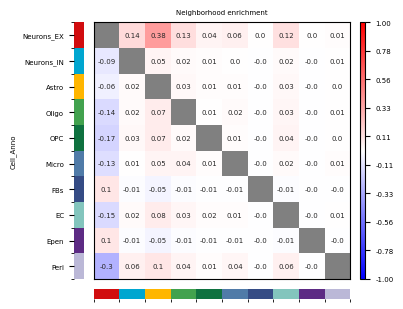

In [26]:
cc.gr.nhood_enrichment(
    adata_subgroup2,
    cluster_key='Cell_Anno',###
)

cc.pl.nhood_enrichment(
    adata_subgroup2,
    cluster_key='Cell_Anno',
    annotate=True,
    vmin=-1,
    vmax=1,
    figsize=(3,3),
    fontsize=5,
)
plt.savefig('/mnt/e/niche3 neiborhood.pdf', bbox_inches='tight',  dpi=500 )
####

In [15]:
adata

AnnData object with n_obs × n_vars = 12533 × 13877
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'group', 'Celltype', 'banksy_niche', 'Type', 'n_counts', 'batch', '_scvi_batch', '_scvi_labels'
    var: 'n_counts'
    uns: 'spatial', 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'spatial_neighbors', 'Celltype_colors'
    obsm: 'spatial', 'X_scVI'
    layers: 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [64]:
#
adata.obs['condition'] = adata.obs['Type'].str.split('-').str[0].astype('category')
cc.gr.diff_nhood_enrichment(
    adata_subgroup1,
    cluster_key='Cell_Anno',
    condition_key='condition',
    library_key='Type',
    pvalues=True,
    n_jobs=15,
    n_perms=100
)

  0%|          | 0/100 [00:00<?, ?it/s]

Process ForkProcess-13:
Process ForkProcess-10:
Process ForkProcess-5:
Process ForkProcess-8:
Process ForkProcess-15:
Process ForkProcess-3:
Process ForkProcess-16:
Process ForkProcess-11:
Process ForkProcess-2:
Process ForkProcess-4:
Process ForkProcess-12:
Process ForkProcess-6:
Process ForkProcess-9:
Process ForkProcess-14:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/root/miniconda3/envs/cellcharter/lib/python3.12/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/root/miniconda3/envs/cellcharter/lib/python3.12

KeyboardInterrupt: 

In [ ]:
#
cc.pl.diff_nhood_enrichment(
    adata_subgroup1,
    cluster_key='Celltype',
    condition_key='condition',
    condition_groups=['IWD', 'CWD'],
    annotate=True,
    figsize=(3,3),
    significance=0.05,
    fontsize=5
)
plt.savefig( '/mnt/e/AD_analysis/Hip_neibor_diff_enrich.pdf',  bbox_inches='tight',  dpi=500)
plt.close() #

In [29]:
 # 示例筛选条件
#adata1 = adata[adata.obs['banksy_niche'] == 'niche_3', :].copy() 
sq.gr.co_occurrence(adata_subgroup2, cluster_key="Cell_Anno")

AnnData object with n_obs × n_vars = 434195 × 5006
    obs: 'orig.ident', 'nCount_Xenium', 'nFeature_Xenium', 'group', 'Type', 'nCount_SCT', 'nFeature_SCT', 'Cell_Anno', 'region', 'barcode', 'n_counts', 'batch', 'condition'
    var: 'n_counts'
    uns: 'log1p', 'spatial_neighbors', 'Celltype_colors', 'Cell_Anno_colors'
    obsm: 'X_spatial', 'spatial'
    layers: 'counts'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [ ]:

sq.pl.co_occurrence(
    adata_subgroup2,
    cluster_key="Cell_Anno",
    clusters="Neurons_EX",
    figsize=(5, 3.5),palette=celltype_colors
)
#plt.savefig('/mnt/e/ST_time_AS/visiumHD/15w_co_occurrence.pdf',  bbox_inches='tight', dpi=500)

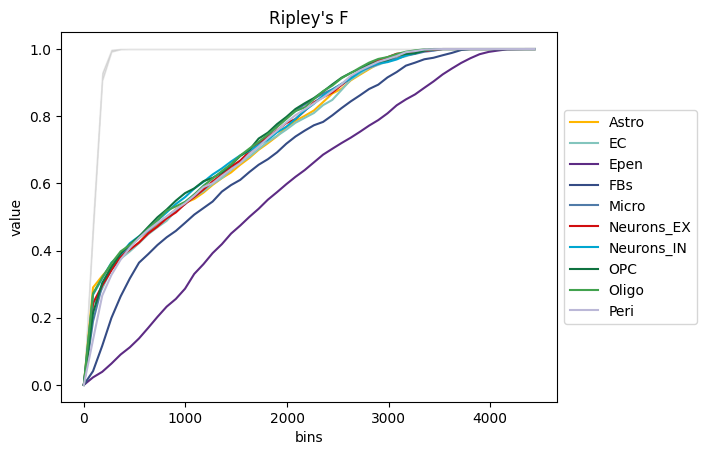

In [51]:

sq.gr.ripley(adata_subgroup2, cluster_key="Cell_Anno")
sq.pl.ripley(adata_subgroup2, cluster_key="Cell_Anno")
plt.savefig('/mnt/e/AD_analysis/CWD Hy_ripley.pdf',  bbox_inches='tight', dpi=500)

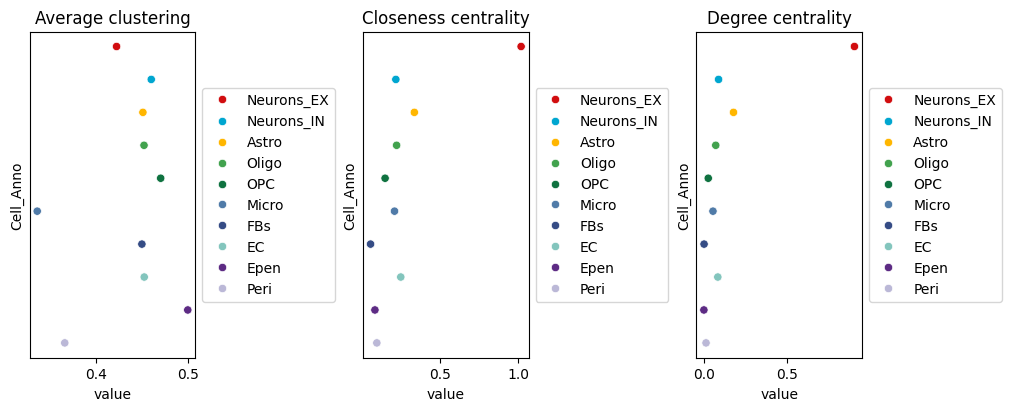

In [29]:


sq.gr.centrality_scores(adata_subgroup2, "Cell_Anno")
sq.pl.centrality_scores(adata_subgroup2, "Cell_Anno", figsize=(10, 4))
plt.savefig('/mnt/e/AD_analysis/niche2__centrality_scores.pdf',  bbox_inches='tight', dpi=500)

In [124]:
cc.gr.connected_components(adata, cluster_key='Celltype')
cc.tl.boundaries(adata, min_hole_area_ratio=0.1)
cc.tl.linearity(adata)
cc.tl.curl(adata)
#cc.tl.elongation(adata)

/tmp/ipykernel_767/1452181922.py:3: FutureWarning: linearity is deprecated and will be removed in the next release. Please use `linearity_metric` instead.
  cc.tl.linearity(adata)
/tmp/ipykernel_767/1452181922.py:4: FutureWarning: curl is deprecated and will be removed in the next release. Please use `curl_metric` instead.
  cc.tl.curl(adata)


In [98]:
adata.obs['condition'] = adata.obs['Type'].str.split('-').str[0].astype('category')
adata.obs['Type'].unique()
adata.obs['Type']

0        10w HFD
1        10w HFD
2        10w HFD
3        10w HFD
4        10w HFD
          ...   
12095    15w HFD
12096    15w HFD
12097    15w HFD
12098    15w HFD
12099    15w HFD
Name: Type, Length: 12100, dtype: category
Categories (4, object): ['0w HFD', '5w HFD', '10w HFD', '15w HFD']

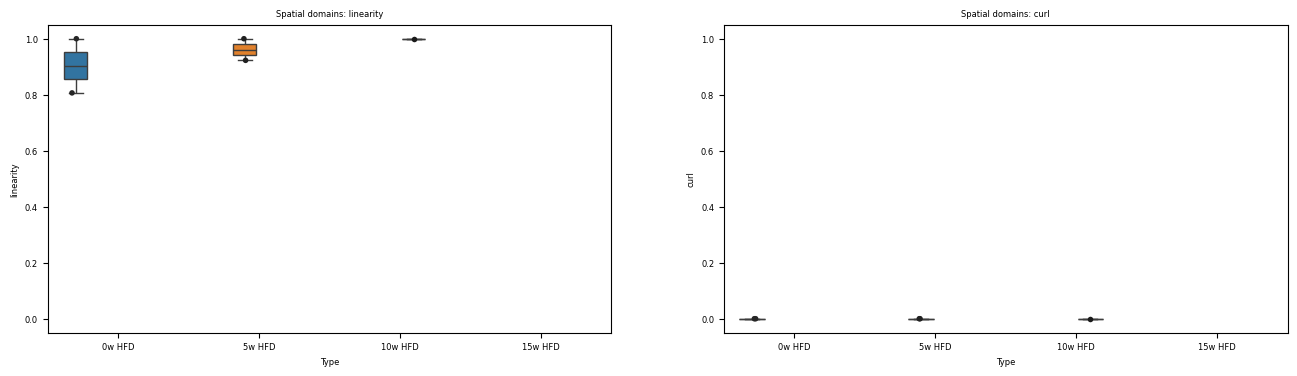

In [133]:
cc.pl.shape_metrics(
    adata,
    condition_key='condition', 
    condition_groups=['0w HFD', '5w HFD', '10w HFD', '15w HFD'],
    cluster_key='Type', 
    figsize=(8,4),
    fontsize=6
)